# Puntos y cajas: entrenamiento y evaluación
Ejecuta las celdas en orden, con `juego.py` en la misma carpeta. Requiere Python 3, Jupyter y matplotlib.

El recorrido es: representar el juego → observar una partida aleatoria → medir 1.000 partidas aleatorias → definir y entrenar el agente → comparar epsilon → guardar el elegido → demostrar una partida completa.

`juego.py` administra las reglas y el estado; este notebook decide acciones, entrena y evalúa. El único archivo generado es **`modelos/agente.pickle`**. Los resultados, las gráficas y los tableros se muestran en el notebook.

In [1]:
import random
from juego import Juego, MODELO, JUGADOR, SIMBOLOS, EXTREMOS

# Única semilla para reproducir el experimento completo.
SEMILLA = 42
random.seed(SEMILLA)

## Acciones y estado
El tablero tiene 3×3 puntos y cuatro cajas. Los puntos se numeran por filas: 0, 1, 2 arriba; 3, 4, 5 al centro; 6, 7, 8 abajo. Cada acción es un entero entre 0 y 11 que identifica una línea sin dirección. La acción 0 une los puntos 0 y 1; la 6 une los puntos 0 y 3.

El estado es `(lineas, propietarios, turno)`: doce indicadores de líneas ocupadas, cuatro propietarios (0 para caja libre, M o J para caja capturada) y el turno actual. Los puntajes se deducen de las cajas y no se duplican en el estado.

`obtener_estado()` devuelve una instantánea inmutable que se utiliza como clave de V. Dos juegos con la misma posición, propietarios y turno consultan el mismo valor. `jugar(accion)` determina quién juega a partir del turno interno y lo conserva cuando corresponde por una captura.

In [2]:
for accion, extremos in enumerate(EXTREMOS):
    print(f'Acción {accion:2}: puntos {extremos[0]}–{extremos[1]}')

juego = Juego(jugador_inicial=MODELO)
print(juego.representar())
print('Líneas libres:', juego.movimientos_validos())

Acción  0: puntos 0–1
Acción  1: puntos 1–2
Acción  2: puntos 3–4
Acción  3: puntos 4–5
Acción  4: puntos 6–7
Acción  5: puntos 7–8
Acción  6: puntos 0–3
Acción  7: puntos 1–4
Acción  8: puntos 2–5
Acción  9: puntos 3–6
Acción 10: puntos 4–7
Acción 11: puntos 5–8
 +    0    +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         10        11
 +    4    +    5    + 
M: 0 | J: 0
Turno: M
Líneas libres: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]


## Simulación de una partida aleatorio contra aleatorio
Ambos jugadores eligen uniformemente entre las líneas libres. Aunque uno esté identificado como M, en esta etapa todavía actúa al azar. Consultamos el turno antes de cada acción porque capturar una caja permite volver a jugar.

`mostrar` permite observar la partida o ejecutarla en silencio. El jugador inicial se pasa a `Juego`; si se omite o vale `None`, la clase sortea quién comienza. La demostración siguiente fija el inicio en M.

In [3]:
# La selección se limita a líneas libres; una acción identifica una línea.
def elegir_accion_aleatoria(juego):
    return random.choice(juego.movimientos_validos())


def ejecutar_partida(jugador_inicial=None, mostrar=True):
    # Si jugador_inicial es None, Juego sortea el inicio; si se indica M o J, lo respeta.
    juego = Juego(jugador_inicial)
    if mostrar:
        print(juego.representar())
    while not juego.terminado():
        # El juego decide el turno: una captura permite que el mismo jugador continúe.
        jugador = juego.obtener_turno()
        accion = elegir_accion_aleatoria(juego)
        resultado = juego.jugar(accion)
        if mostrar:
            print(f'\n{SIMBOLOS[jugador]} elige línea {accion}; '
                  f'captura {len(resultado["cajas_capturadas"])} caja(s).')
            print(juego.representar())
    return juego

In [4]:
partida = ejecutar_partida(jugador_inicial=MODELO)

 +    0    +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         10        11
 +    4    +    5    + 
M: 0 | J: 0
Turno: M

M elige línea 10; captura 0 caja(s).
 +    0    +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         |         11
 +    4    +    5    + 
M: 0 | J: 0
Turno: J

J elige línea 1; captura 0 caja(s).
 +    0    + ------- + 
 6         7         8 
 +    2    +    3    + 
 9         |         11
 +    4    +    5    + 
M: 0 | J: 0
Turno: M

M elige línea 0; captura 0 caja(s).
 + ------- + ------- + 
 6         7         8 
 +    2    +    3    + 
 9         |         11
 +    4    +    5    + 
M: 0 | J: 0
Turno: J

J elige línea 6; captura 0 caja(s).
 + ------- + ------- + 
 |         7         8 
 +    2    +    3    + 
 9         |         11
 +    4    +    5    + 
M: 0 | J: 0
Turno: M

M elige línea 5; captura 0 caja(s).
 + ------- + ------- + 
 |         7         8 
 +    2    +    3    + 
 9         |         11
 +    4    + 

## Por qué ganar al azar no equivale necesariamente al 50 %
Cuando ambos participantes usan la misma elección uniforme de líneas libres y equilibramos quién comienza, tienen la misma probabilidad de ganar. Como también pueden empatar:

$$P(\text{victoria de M})=P(\text{derrota de M})=\frac{1-P(\text{empate})}{2}.$$

Por tanto, el 50 % corresponde a $P(\text{victoria})+0.5P(\text{empate})$, no necesariamente al porcentaje de victorias. Los tres resultados no son equiprobables.

Usamos las frecuencias de las 1.000 partidas como estimaciones experimentales. Pueden variar por azar y no tienen por qué dar exactamente la misma cantidad de victorias y derrotas. No hace falta enumerar todas las partidas posibles para comparar el agente con esta referencia.

## Referencia experimental: 1.000 partidas aleatorias
Alternamos el inicio: 500 partidas comienzan con M y 500 con J. Registramos victorias, derrotas y empates desde la perspectiva de M, y calculamos sus porcentajes sobre el total.

Esta referencia mide el rendimiento sin aprendizaje. Se conservan comprobaciones dentro de la simulación para confirmar que se consumen doce líneas, se reparten cuatro cajas y se respetan los turnos por captura. Los porcentajes obtenidos se reutilizan en la tabla comparativa y en las líneas de referencia de las gráficas.

In [5]:
# Referencia sin entrenamiento: ambos jugadores actuarán al azar.
cantidadPartidas = 1000

# Contadores por resultado: 0 = empate, MODELO = victoria de M, JUGADOR = derrota de M.
resultadosPartidas = {
    0: 0,
    MODELO: 0,
    JUGADOR: 0
}

for numeroPartida in range(cantidadPartidas):

    # Alternamos el inicio para que cada participante comience la mitad de las partidas.
    jugadorInicial = MODELO if numeroPartida % 2 == 0 else JUGADOR

    partida = Juego(jugadorInicial)

    # Cada partida debe consumir las doce líneas del tablero.
    cantidadMovimientosRealizados = 0

    while not partida.terminado():

        # Se conserva para verificar el turno después de la captura.
        jugadorAntesDelMovimiento = partida.obtener_turno()

        accionAleatoria = elegir_accion_aleatoria(partida)

        resultadoMovimiento = partida.jugar(accionAleatoria)

        cantidadMovimientosRealizados += 1

        assert (
            len(partida.movimientos_validos())
            == 12 - cantidadMovimientosRealizados
        )

        if not partida.terminado():

            # Capturar una o dos cajas mantiene el turno; no capturar lo cambia.
            if resultadoMovimiento['cajas_capturadas']:

                assert partida.obtener_turno() == jugadorAntesDelMovimiento

            else:

                assert partida.obtener_turno() != jugadorAntesDelMovimiento


    assert cantidadMovimientosRealizados == 12

    # Al finalizar deben estar asignadas las cuatro cajas.
    assert sum(partida.puntajes().values()) == 4

    assert partida.obtener_turno() is None

    ganadorPartida = partida.ganador()

    resultadosPartidas[ganadorPartida] += 1

    # La acción rechazada después del final no debe modificar el estado.
    estadoAntesDelIntentoInvalido = partida.obtener_estado()

    try:
        # Intento deliberado después del final: se espera ValueError.
        partida.jugar(0)

    # Recibir este error significa que se rechazó correctamente la acción.
    except ValueError:

        pass

    else:

        raise AssertionError('Se permitió jugar tras el final')

    assert partida.obtener_estado() == estadoAntesDelIntentoInvalido


print(f'{cantidadPartidas} partidas verificadas.')

# Todos los resultados y porcentajes se interpretan desde la perspectiva de M.
cantidadVictoriasModelo = resultadosPartidas[MODELO]
cantidadDerrotasModelo = resultadosPartidas[JUGADOR]
cantidadEmpates = resultadosPartidas[0]

# Estas tasas simuladas serán la referencia de las gráficas y de la comparación.
porcentajeVictoriasModelo = cantidadVictoriasModelo / cantidadPartidas * 100
porcentajeDerrotasModelo = cantidadDerrotasModelo / cantidadPartidas * 100
porcentajeEmpates = cantidadEmpates / cantidadPartidas * 100

print(
    f'Victorias M: {cantidadVictoriasModelo} '
    f'({porcentajeVictoriasModelo:.2f}%)'
)
print(
    f'Derrotas M: {cantidadDerrotasModelo} '
    f'({porcentajeDerrotasModelo:.2f}%)'
)
print(
    f'Empates: {cantidadEmpates} '
    f'({porcentajeEmpates:.2f}%)'
)

# Referencia de recompensa: victoria = 1, empate = 0.5, derrota = 0.
recompensaMediaAleatoria = (cantidadVictoriasModelo + 0.5 * cantidadEmpates) / cantidadPartidas

1000 partidas verificadas.
Victorias M: 427 (42.70%)
Derrotas M: 427 (42.70%)
Empates: 146 (14.60%)


## Agente tabular
Base: Agent de 01_introduccion y 00_intro. Guarda V(estado), explora con epsilon y actualiza en orden inverso al terminar. El objetivo del estado anterior es el valor recién actualizado del siguiente: no se mantiene constante la recompensa en todo el recorrido. No es Q-learning ni Monte Carlo puro.

Usamos alfa=0.1, comparamos cuatro epsilon y mantenemos el valor inicial=0.5. Recompensas finales: victoria=1, empate=0.5, derrota=0. El objetivo esperado combina victorias y medio punto por empate; no es únicamente probabilidad de victoria. Los valores terminales también se aprenden como en el cuadernillo.

La explotación simula una sola acción legal por copia y consulta su valor. Los empates de valor se resuelven al azar. Las copias no se registran como experiencia. Todas las valoraciones son desde la perspectiva de M.

### Qué contiene realmente el modelo
No hay una red neuronal ni PyTorch. El modelo es un **diccionario de valores V(s)**: cada clave describe un estado y cada número estima qué tan favorable resulta para M. Un estado desconocido se consulta con valor inicial 0.5. Esto es una estimación neutral elegida por nosotros, no una probabilidad calculada ni un empate garantizado.

- **Puntos del juego:** cajas capturadas, de 0 a 4 por jugador.
- **Recompensa:** resultado final traducido a 1, 0.5 o 0.
- **Valor aprendido:** número que el agente actualiza y consulta para comparar movimientos. No equivale directamente a porcentaje de victorias.
- **Epsilon:** probabilidad de explorar al decidir una acción durante el entrenamiento. Con epsilon 0.2, en aproximadamente el 20 % de esas decisiones elige una línea legal al azar; esa línea también podría ser la mejor.
- **Alfa:** fracción de la diferencia con el objetivo que se incorpora en cada actualización. Con alfa 0.1 conserva el 90 % del valor anterior y toma un 10 % del objetivo.

### Cómo decide una acción
Primero puede explorar. Si no explora, copia el juego para cada línea libre, juega esa línea en la copia y consulta V del estado resultante. Finalmente escoge una de las acciones con mayor valor. Solo anticipa **una jugada** por candidato: no recorre todo el árbol ni conoce la recompensa futura real. Si dos acciones tienen igual valor, elige entre ellas al azar para no favorecer siempre la primera.

### Cómo aprende después de una partida
Registramos los estados realmente visitados tras cada jugada. Al finalizar, recorremos la lista desde el último al primero y aplicamos:

$$V(s)\leftarrow V(s)+\alpha[\text{objetivo}-V(s)].$$

Para el estado terminal, el objetivo es la recompensa final. Para el anterior, el objetivo será el valor **recién actualizado** del siguiente estado visitado. Por eso cambiamos `objetivo` dentro del bucle: la recompensa no se copia idéntica sobre todos los estados.

Ejemplo con victoria, alfa 0.1 y valores anteriores 0.5: el último estado pasa a $0.5+0.1(1-0.5)=0.55$; el anterior pasa a $0.5+0.1(0.55-0.5)=0.505$. En muchas partidas la información se propaga hacia estados anteriores. No usamos una etiqueta supervisada que diga cuál era la acción correcta.

Esta es la actualización hacia atrás basada en valores de los cuadernillos introductorios. Aprende a partir de otros valores estimados (*bootstrapping*); no es la actualización de Q-learning ni el método que asigna directamente el retorno final a cada estado. Todos los estados, incluso después de jugadas de J, se valoran desde la perspectiva de M. J no tiene un modelo que aprenda.


In [6]:
# Agente tabular basado en los cuadernillos introductorios: aprende V(estado).
class Agente:
    def __init__(self, alfa=0.1, epsilon=0.2):
        if not 0 < alfa <= 1 or not 0 <= epsilon <= 1:
            raise ValueError('Parámetros fuera de rango')
        # Fracción de la diferencia con el objetivo incorporada en cada actualización.
        self.alfa = alfa
        # Probabilidad de explorar durante el entrenamiento.
        self.epsilon = epsilon
        # Tabla aprendida: estado completo → valor estimado desde la perspectiva de M.
        self.valores = {}
        # Trayectoria temporal de una partida; la tabla V persiste entre partidas.
        self.historial = []

    def elegir_accion(self, juego, rng, explorar=True):
        acciones = juego.movimientos_validos()
        if not acciones or juego.obtener_turno() != MODELO:
            raise ValueError('El agente solo actúa durante el turno de M')
        # Exploración epsilon-greedy: se elige una acción legal al azar.
        if explorar and rng.random() < self.epsilon:
            return rng.choice(acciones)
        # Explotación: se reúnen todas las acciones con el mayor valor aprendido.
        mejores = []
        mejor_valor = float('-inf')
        for accion in acciones:
            # Simulamos alternativas sin alterar la partida real.
            copia = juego.copiar()
            # Solo anticipamos esta jugada; no recorremos todo el árbol de partidas.
            copia.jugar(accion)
            # Un estado todavía desconocido vale 0.5; consultarlo no lo añade a la tabla.
            valor = self.valores.get(copia.obtener_estado(), 0.5)
            if valor > mejor_valor:
                mejor_valor = valor
                # Un máximo nuevo descarta las alternativas que dejaron de ser las mejores.
                mejores = [accion]
            elif valor == mejor_valor:
                # Incluimos también las alternativas que empatan con el máximo.
                mejores.append(accion)
        # Desempate aleatorio para no favorecer siempre la primera línea.
        return rng.choice(mejores)

    def registrar(self, juego):
        # Registra únicamente estados reales visitados, sin guardar las copias de exploración.
        self.historial.append(juego.obtener_estado())

    def aprender(self, recompensa):
        # El primer estado actualizado es el terminal y usa la recompensa final.
        objetivo = recompensa
        # Propagamos la información desde el final hacia el comienzo de la partida.
        for estado in reversed(self.historial):
            # La primera actualización de un estado parte del valor neutral 0.5.
            anterior = self.valores.get(estado, 0.5)
            # V nuevo = V anterior + alfa × (objetivo − V anterior). Aquí se produce el aprendizaje.
            self.valores[estado] = anterior + self.alfa * (objetivo - anterior)
            # El estado previo usa el valor recién actualizado del siguiente estado visitado.
            objetivo = self.valores[estado]
        # Se limpia la trayectoria; se conservan todos los valores aprendidos.
        self.historial.clear()


# Recompensa desde la perspectiva de M, disponible al terminar la partida.
def recompensa_final(juego):
    ganador = juego.ganador()
    if ganador is None:
        raise ValueError('La partida debe haber terminado')
    # Victoria de M = 1; empate = 0.5; derrota de M = 0.
    return 1.0 if ganador == MODELO else 0.5 if ganador == 0 else 0.0

## Partidas y evaluación
Solo el entrenamiento registra estados y llama a aprender. Registramos después de cada acción de ambos participantes. La evaluación usa su propio generador aleatorio para no alterar la secuencia de entrenamiento. Un agente vacío con desempates uniformes proporciona la referencia aleatoria.

### Una función de partida, dos modos
`entrenar=True` permite explorar, registra experiencias y actualiza al final. Con el valor predeterminado `False`, solamente juega: no registra ni modifica V. `mostrar` es independiente: determina si se imprimen los tableros. Durante el entrenamiento vale `False` para evitar cientos de miles de líneas de salida.

Se registra después de **cada acción de ambos jugadores**, porque lo que hace J también modifica el estado que experimenta M. El juego decide si mantiene o cambia el turno; el bucle únicamente consulta `obtener_turno()` antes de actuar. Si M captura una caja, puede volver a elegir inmediatamente.

### Cómo leer las métricas
| Métrica | Cálculo e interpretación |
|---|---|
| Victorias (%) | 100 × victorias de M / partidas. |
| Empates (%) | 100 × empates / partidas. |
| Derrotas (%) | 100 × victorias de J / partidas. Las tres tasas suman 100 %. |
| Cajas M | Promedio de cajas obtenidas por M. |
| Diferencia de cajas | Promedio de puntos de M menos puntos de J; positivo favorece a M. |
| Recompensa media | (victorias + 0.5 × empates) / partidas; está entre 0 y 1. |
| Victorias según inicio | Divide las victorias de M en ese grupo entre las partidas de ese mismo grupo. |

Por ejemplo, con 80 victorias, 10 empates y 10 derrotas en 100 partidas: victorias = 80 % y recompensa media = 0.85. Esta última no debe etiquetarse como 85 % de victorias. No usamos accuracy de clasificación porque aquí no existe una etiqueta de acción correcta para cada turno.

`por_inicio` guarda dos contadores por cada jugador inicial: `[victorias_de_M, partidas]`. Reiniciar el generador de evaluación con la misma semilla facilita la repetición, aunque distintas políticas pueden producir trayectorias distintas.


In [7]:
# Una misma función ejecuta entrenamiento, evaluación y demostración.
def partida_agente(agente, inicial, rng, entrenar=False, mostrar=False):
    juego = Juego(inicial)
    if entrenar:
        # Iniciamos una trayectoria nueva sin borrar la tabla de aprendizaje.
        agente.historial.clear()
    if mostrar:
        print(juego.representar())
    while not juego.terminado():
        # El juego decide el turno: una captura permite que el mismo jugador continúe.
        jugador = juego.obtener_turno()
        if jugador == MODELO:
            # Epsilon se activa solo al entrenar; al evaluar se consulta lo aprendido.
            accion = agente.elegir_accion(juego, rng, explorar=entrenar)
        else:
            # El oponente J siempre usa una política aleatoria uniforme.
            accion = rng.choice(juego.movimientos_validos())
        resultado = juego.jugar(accion)
        if entrenar:
            # Registramos después de ambos jugadores, porque J también modifica el estado.
            agente.registrar(juego)
        if mostrar:
            print(f'\n{SIMBOLOS[jugador]} coloca línea {accion}; '
                  f'captura {len(resultado["cajas_capturadas"])} caja(s): '
                  f'{resultado["cajas_capturadas"]}')
            print(juego.representar())
    if entrenar:
        # Actualización al finalizar cada partida de entrenamiento.
        agente.aprender(recompensa_final(juego))
    return juego


# Mide el rendimiento sin explorar explícitamente ni actualizar V.
def evaluar(agente, partidas=1000):
    if partidas < 2 or partidas % 2:
        raise ValueError('Usa un número par de partidas, al menos 2')
    # Generador separado para que las evaluaciones no consuman el de entrenamiento.
    rng = random.Random(SEMILLA)
    conteo = {0: 0, MODELO: 0, JUGADOR: 0}
    # Por inicio: [victorias de M, partidas del grupo], para medir la ventaja de comenzar.
    por_inicio = {MODELO: [0, 0], JUGADOR: [0, 0]}
    cajas_m = diferencia = 0
    for numero in range(partidas):
        inicial = MODELO if numero % 2 == 0 else JUGADOR
        juego = partida_agente(agente, inicial, rng)
        ganador = juego.ganador()
        conteo[ganador] += 1
        por_inicio[inicial][0] += ganador == MODELO
        por_inicio[inicial][1] += 1
        puntos = juego.puntajes()
        cajas_m += puntos[MODELO]
        # Margen de cajas: complementa las tasas de victoria, empate y derrota.
        diferencia += puntos[MODELO] - puntos[JUGADOR]
    return {
        'victorias_pct': 100 * conteo[MODELO] / partidas,
        'empates_pct': 100 * conteo[0] / partidas,
        'derrotas_pct': 100 * conteo[JUGADOR] / partidas,
        'cajas_m': cajas_m / partidas,
        'diferencia_cajas': diferencia / partidas,
        'recompensa_media': (conteo[MODELO] + 0.5 * conteo[0]) / partidas,
        'victorias_inicia_m_pct': 100 * por_inicio[MODELO][0] / por_inicio[MODELO][1],
        'victorias_inicia_j_pct': 100 * por_inicio[JUGADOR][0] / por_inicio[JUGADOR][1],
    }

## Experimento: influencia de epsilon
Comparamos epsilon = **0, 0.1, 0.2 y 0.4**, con un solo entrenamiento por valor. Usamos una única semilla, `SEMILLA = 42`, definida al inicio. Cada agente comienza con una tabla vacía y el generador se reinicia con esa misma semilla para hacer reproducible la comparación. Alfa permanece en 0.1.

Entrenamos **30.000 partidas por agente** y evaluamos **cada 1.000 partidas**, incluyendo el punto inicial sin entrenamiento. Cada evaluación contiene 1.000 partidas sin aprender ni explorar explícitamente. El generador de evaluación está separado del de entrenamiento, pero ambos usan la misma semilla; así medir no altera el entrenamiento.

Las curvas permiten observar si las ganancias se reducen hacia el final y justificar el presupuesto de entrenamiento. Una curva aproximadamente estable sugiere estabilización del rendimiento medido; **no demuestra convergencia matemática** ni garantiza que más entrenamiento no ayude. Epsilon cero conserva el desempate aleatorio entre acciones de igual valor.

### Qué significa cada cantidad
`EPISODIOS` cuenta partidas completas de entrenamiento, no movimientos. Una partida tiene doce movimientos totales. Cuatro epsilon × 30.000 partidas = 120.000 partidas de entrenamiento. El punto 0 solo evalúa al agente vacío y no cuenta como entrenamiento.

`INTERVALO` controla cada cuánto medimos: cada 1.000 episodios. `PARTIDAS_EVALUACION` controla cuántas partidas usamos para cada medición: también 1.000, pero es una cantidad distinta. Hay 31 mediciones por epsilon (0, 1.000, …, 30.000); esas partidas no actualizan el modelo. Aprender sigue ocurriendo **al final de cada partida de entrenamiento**, no cada 1.000.

`agentes` mantiene en memoria los cuatro objetos ya entrenados. `metricas` almacena una lista de diccionarios con las mediciones para dibujar las curvas. Ninguna de estas listas se exporta a archivos. El reloj mide tiempo de ejecución y no participa en el aprendizaje.


In [8]:
from time import perf_counter

# Mantenemos alfa fijo para comparar solamente el efecto de epsilon.
ALFA = 0.1
# Se entrena un agente nuevo para cada intensidad de exploración.
EPSILONS = [0.0, 0.1, 0.2, 0.4]
# Presupuesto de partidas completas por epsilon; las curvas muestran su evolución.
EPISODIOS = 30000
# Se registra un punto de evaluación cada mil partidas de entrenamiento.
INTERVALO = 1000
# Cada punto resume mil partidas adicionales, que no entrenan al agente.
PARTIDAS_EVALUACION = 1000

agentes = {}
metricas = []
inicio = perf_counter()
for epsilon in EPSILONS:
    # Cada comparación parte de una tabla vacía.
    candidato = Agente(ALFA, epsilon)
    # Reiniciamos con la misma semilla para cada configuración.
    rng_entrenamiento = random.Random(SEMILLA)
    # El punto cero evalúa sin entrenar; los siguientes episodios juegan y aprenden.
    for episodio in range(EPISODIOS + 1):
        if episodio > 0:
            # Alternamos también quién empieza durante el entrenamiento.
            inicial = MODELO if (episodio - 1) % 2 == 0 else JUGADOR
            partida_agente(candidato, inicial, rng_entrenamiento, entrenar=True)
        if episodio % INTERVALO == 0:
            # La comprobación posterior asegura que evaluar no cambia V.
            antes = candidato.valores.copy()
            fila = evaluar(candidato, PARTIDAS_EVALUACION)
            assert candidato.valores == antes and not candidato.historial
            # Identificamos la configuración y el momento de cada medición.
            fila.update(epsilon=epsilon, episodios=episodio)
            metricas.append(fila)
    # Retenemos el agente final de cada configuración para seleccionar uno después.
    agentes[epsilon] = candidato
    print(f"epsilon={epsilon:.1f}: victorias={fila['victorias_pct']:.1f}%, "
          f"empates={fila['empates_pct']:.1f}%, derrotas={fila['derrotas_pct']:.1f}%")
print(f'Tiempo total: {perf_counter() - inicio:.1f} segundos')

epsilon=0.0: victorias=79.3%, empates=14.4%, derrotas=6.3%
epsilon=0.1: victorias=83.3%, empates=13.2%, derrotas=3.5%
epsilon=0.2: victorias=84.7%, empates=11.0%, derrotas=4.3%
epsilon=0.4: victorias=84.1%, empates=11.0%, derrotas=4.9%
Tiempo total: 119.0 segundos


## Comparación y elección de epsilon
La tabla compara los cuatro agentes al terminar 30.000 partidas. Para fundamentar la elección con el porcentaje de partidas ganadas, seleccionamos el epsilon con **mayor porcentaje de victorias en esta evaluación**. En empate conservamos el primero de la lista.

El agente aprende con recompensas 1, 0.5 y 0, mientras que aquí usamos victorias como criterio de selección. Mostramos también recompensa media, empates y derrotas para distinguir ambas medidas. El resultado corresponde a esta única semilla y al rival aleatorio.

La selección compara las cuatro mediciones al llegar a 30.000 partidas y elige el epsilon con mayor porcentaje de victorias. En caso de empate conserva el primero.

`agente = agentes[EPSILON]` selecciona el objeto que ya fue entrenado; no lo vuelve a entrenar ni copia su tabla. Guardaremos este modelo final de la configuración elegida. No buscamos el mejor punto intermedio de cada curva.


In [9]:
claves = ['victorias_pct', 'empates_pct', 'derrotas_pct', 'recompensa_media',
          'victorias_inicia_m_pct', 'victorias_inicia_j_pct']
resumen = [m for m in metricas if m['episodios'] == EPISODIOS]

print('Configuración      V%      E%      D%    Recompensa   V% inicia M   V% inicia J')
print(f'Aleatorio (1000)  {porcentajeVictoriasModelo:6.2f}  {porcentajeEmpates:6.2f}  '
      f'{porcentajeDerrotasModelo:6.2f}     {recompensaMediaAleatoria:.3f}             —             —')
for r in resumen:
    print(f"epsilon={r['epsilon']:.1f}       {r['victorias_pct']:6.2f}  {r['empates_pct']:6.2f}  "
          f"{r['derrotas_pct']:6.2f}     {r['recompensa_media']:.3f}        "
          f"{r['victorias_inicia_m_pct']:6.2f}        {r['victorias_inicia_j_pct']:6.2f}")
# Elegimos el mayor porcentaje de victorias al finalizar los 30000 episodios.
EPSILON = max(resumen, key=lambda r: r['victorias_pct'])['epsilon']
# Se utiliza el objeto ya entrenado; no se entrena otra vez después de seleccionarlo.
agente = agentes[EPSILON]
print(f'\nElegido: epsilon={EPSILON}, después de {EPISODIOS} partidas.')

Configuración      V%      E%      D%    Recompensa   V% inicia M   V% inicia J
Aleatorio (1000)   42.70   14.60   42.70     0.500             —             —
epsilon=0.0        79.30   14.40    6.30     0.865         91.20         67.40
epsilon=0.1        83.30   13.20    3.50     0.899         89.20         77.40
epsilon=0.2        84.70   11.00    4.30     0.902         92.80         76.60
epsilon=0.4        84.10   11.00    4.90     0.896         91.20         77.00

Elegido: epsilon=0.2, después de 30000 partidas.


## Curvas de aprendizaje
Cada curva representa **un agente con un epsilon diferente**. Cada punto corresponde a una evaluación cada 1.000 partidas de entrenamiento. No se calculan promedios entre semillas ni bandas de variación. Las líneas horizontales indican el rendimiento medido en las 1.000 partidas aleatorias iniciales.

Para la defensa: observa la subida inicial y compara la evolución de los últimos puntos. Si aún hay una tendencia ascendente, explica que 30.000 es el presupuesto elegido y que todavía podría mejorar. Las oscilaciones son esperables: no se exige una mejora en cada punto.

`plt.subplots(1, 2)` crea una figura con una fila y dos paneles. `fig` representa la figura completa y `ejes[0]` / `ejes[1]` cada panel. Cada llamada a `plot` añade una curva. Los puntos se dibujan cada 1.000 episodios aunque las etiquetas numéricas grandes del eje aparezcan cada 5.000 para facilitar la lectura. `plt.show()` muestra la figura aquí; no crea un archivo de imagen.


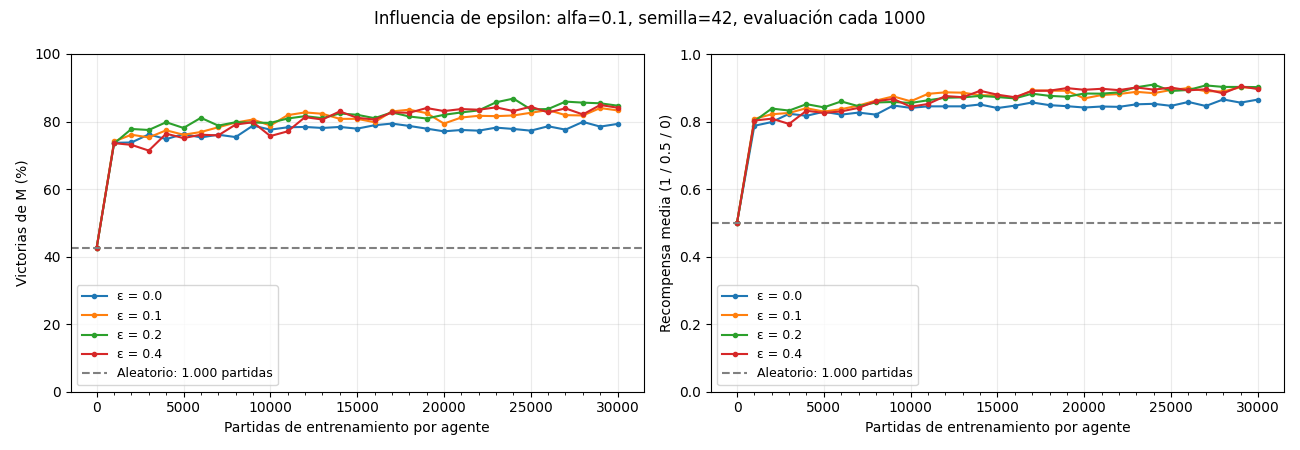

In [10]:
import matplotlib.pyplot as plt

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for epsilon in EPSILONS:
    filas = [m for m in metricas if m['epsilon'] == epsilon]
    x = [m['episodios'] for m in filas]
    ejes[0].plot(x, [m['victorias_pct'] for m in filas], marker='o', markersize=3, label=f'ε = {epsilon}')
    ejes[1].plot(x, [m['recompensa_media'] for m in filas], marker='o', markersize=3, label=f'ε = {epsilon}')
# Referencia experimental obtenida antes del entrenamiento.
ejes[0].axhline(porcentajeVictoriasModelo, color='gray', linestyle='--', label='Aleatorio: 1.000 partidas')
ejes[1].axhline(recompensaMediaAleatoria, color='gray', linestyle='--', label='Aleatorio: 1.000 partidas')
ejes[0].set_ylabel('Victorias de M (%)')
ejes[1].set_ylabel('Recompensa media (1 / 0.5 / 0)')
ejes[0].set_ylim(0, 100)
ejes[1].set_ylim(0, 1)
for eje in ejes:
    eje.set_xlabel('Partidas de entrenamiento por agente')
    eje.set_xticks(range(0, EPISODIOS + 1, 5000))
    eje.set_xticks(range(0, EPISODIOS + 1, INTERVALO), minor=True)
    eje.grid(alpha=0.25)
    eje.legend(fontsize=9)
fig.suptitle(f'Influencia de epsilon: alfa={ALFA}, semilla={SEMILLA}, evaluación cada {INTERVALO}')
fig.tight_layout()
plt.show()

## Evaluación ampliada del agente elegido
Medimos 5.000 partidas, manteniendo la misma semilla y alternando quién comienza. Comparamos también un agente vacío, que se comporta como aleatorio. Esta evaluación reutiliza la semilla de validación, por lo que **no se presenta como una prueba independiente**. No cambiamos el epsilon elegido a partir de este resultado.

Crear `Agente()` sin entrenarlo deja su tabla vacía: todas las acciones simuladas valen 0.5, y el desempate uniforme hace que M sea aleatorio. La evaluación del agente entrenado mantiene su tabla intacta. Se imprimen ambos resultados lado a lado para demostrar la mejora respecto a esa referencia.


In [11]:
antes = agente.valores.copy()
# Medición ampliada del agente elegido; reutiliza la misma semilla.
final = evaluar(agente, partidas=5000)
# Un agente vacío desempata uniformemente y se comporta como aleatorio.
base_final = evaluar(Agente(), partidas=5000)
assert agente.valores == antes and not agente.historial
print('Métrica                       Aleatorio    Entrenado')
for clave in claves:
    print(f'{clave:29} {base_final[clave]:9.3f}    {final[clave]:9.3f}')

Métrica                       Aleatorio    Entrenado
victorias_pct                    41.880       84.620
empates_pct                      15.680       10.660
derrotas_pct                     42.440        4.720
recompensa_media                  0.497        0.899
victorias_inicia_m_pct           42.320       93.320
victorias_inicia_j_pct           41.440       75.920


### Interpretación
La tabla de selección usa 1.000 partidas por agente. La evaluación ampliada usa 5.000: sus porcentajes pueden diferir. Se eligió el mejor epsilon **entre los cuatro probados bajo este experimento**, sin afirmar que sea universalmente óptimo. Una sola partida de demostración no sustituye estas métricas.

## Guardar y cargar el modelo elegido
Guardamos únicamente **`modelos/agente.pickle`**: contiene la tabla V y la configuración del agente elegido (alfa, epsilon, semilla, episodios, descripción del estado y recompensas). Los otros agentes y las métricas permanecen en memoria.

Serializamos los datos de la tabla, sin serializar la clase del notebook. Para recuperar el modelo se define `Agente`, se crea un objeto con la configuración guardada y se le asigna la tabla recuperada. Esta carga no vuelve a entrenar. `juego.py` sigue siendo necesario para representar estados y aplicar las reglas.

La carpeta se crea si hace falta. Ejecutar la celda otra vez reemplaza el modelo guardado. La ruta es relativa a la carpeta de trabajo del notebook. Carga únicamente archivos pickle propios o de confianza.

In [12]:
import pickle
from pathlib import Path

Path('modelos').mkdir(exist_ok=True)

# Solo se persiste la tabla elegida y la configuración con la que fue entrenada.
datos_modelo = {
    'valores': agente.valores,
    'alfa': ALFA,
    'epsilon': EPSILON,
    'semilla': SEMILLA,
    'episodios': EPISODIOS,
    'estado': 'lineas_cajas_turno',
    'recompensas': (1, 0.5, 0),
}

with open('modelos/agente.pickle', 'wb') as archivo:
    pickle.dump(datos_modelo, archivo)

with open('modelos/agente.pickle', 'rb') as archivo:
    datos = pickle.load(archivo)

agente_cargado = Agente(datos['alfa'], datos['epsilon'])
# Recuperamos lo aprendido sin volver a entrenar.
agente_cargado.valores = datos['valores']

assert agente_cargado.valores == agente.valores
print('Modelo elegido guardado y recargado correctamente: modelos/agente.pickle')

Modelo elegido guardado y recargado correctamente: modelos/agente.pickle


## Demostración completa: modelo cargado contra aleatorio
Usamos el modelo recuperado del archivo para confirmar que puede jugar después de guardarlo. `mostrar=True` imprime el tablero inicial y las doce jugadas, las cajas capturadas, los puntajes y el turno siguiente. El último tablero indica el ganador o el empate.

Omitimos `entrenar`, cuyo valor predeterminado es `False`: durante esta demostración el agente no aprende ni activa exploración epsilon. Puede desempatar acciones de igual valor al azar. J sigue eligiendo líneas libres uniformemente. Todos los generadores usan el mismo valor `SEMILLA` definido al inicio.

La salida se imprime directamente en el notebook, **sin crear TXT**. Si VS Code la recorta, usa la opción de salida desplazable del editor. La partida ilustra el funcionamiento; las métricas de miles de partidas son las que permiten valorar su rendimiento.


In [13]:
rng_demostracion = random.Random(SEMILLA)

# Demostración completa con el agente cargado, sin entrenamiento.
demostracion = partida_agente(
    agente=agente_cargado,
    inicial=MODELO,
    rng=rng_demostracion,
    mostrar=True,
)

assert demostracion.terminado()
assert not demostracion.movimientos_validos()

 +    0    +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         10        11
 +    4    +    5    + 
M: 0 | J: 0
Turno: M

M coloca línea 5; captura 0 caja(s): ()
 +    0    +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         10        11
 +    4    + ------- + 
M: 0 | J: 0
Turno: J

J coloca línea 0; captura 0 caja(s): ()
 + ------- +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         10        11
 +    4    + ------- + 
M: 0 | J: 0
Turno: M

M coloca línea 10; captura 0 caja(s): ()
 + ------- +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         |         11
 +    4    + ------- + 
M: 0 | J: 0
Turno: J

J coloca línea 4; captura 0 caja(s): ()
 + ------- +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         |         11
 + ------- + ------- + 
M: 0 | J: 0
Turno: M

M coloca línea 11; captura 0 caja(s): ()
 + ------- +    1    + 
 6         7         8 
 +    2    +    3    + 
 9         |    